In [ ]:
# punto 2
import numpy as np

# Voltajes conocidos
V1 = 10
V6 = 200
# Matriz A
A = np.array([
    [1/30 + 1/35 + 1/10, -1/30, 0, -1/10],
    [-1/30, 1/30 + 1/5 + 1/7, -1/5, -1/7 ],
    [0, -1/5, 1/5 + 1/18, -1/18],
    [-1/10, -1/7, -1/18,   1/10 + 1/7 + 1/18 + 1/5]])

# Vector b
b = np.array([V1/35, 0, 0, V6/5])
# Resolver el sistema
V = np.linalg.solve(A, b)
V2, V3, V4, V5 = V
print(f"V2 = {V2:.4f} V")
print(f"V3 = {V3:.4f} V")
print(f"V4 = {V4:.4f} V")
print(f"V5 = {V5:.4f} V")

#calculo de corrientes:
i23 = (V2 - V3)/30
i21 = (V2 - V1)/35
i25 = (V2 - V5)/10
i35 = (V3 - V5)/7
i45 = (V4 - V5)/18
i56 = (V5 - V6)/5
print(f"i23 = {i23:.4f} A")
print(f"i21 = {i21:.4f} A")
print(f"i25 = {i25:.4f} A")
print(f"i35 = {i35:.4f} A")
print(f"i45 = {i45:.4f} A")
print(f"i56 = {i56:.4f} A")


V2 = 149.1337 V
V3 = 175.4212 V
V4 = 176.4435 V
V5 = 180.1238 V
i23 = -0.8762 A
i21 = 3.9752 A
i25 = -3.0990 A
i35 = -0.6718 A
i45 = -0.2045 A
i56 = -3.9752 A


Eigenvalues:
[4.+0.00000000e+00j 2.+1.68652966e-08j 2.-1.68652966e-08j]

Matrix U:
[[-0.57735027+0.00000000e+00j -0.57735027+9.73718355e-09j
  -0.57735027-9.73718355e-09j]
 [ 0.57735027+0.00000000e+00j  0.57735027+0.00000000e+00j
   0.57735027-0.00000000e+00j]
 [-0.57735027+0.00000000e+00j  0.57735027-9.73718355e-09j
   0.57735027+9.73718355e-09j]]

Matrix D:
[[4.+0.00000000e+00j 0.+0.00000000e+00j 0.+0.00000000e+00j]
 [0.+0.00000000e+00j 2.+1.68652966e-08j 0.+0.00000000e+00j]
 [0.+0.00000000e+00j 0.+0.00000000e+00j 2.-1.68652966e-08j]]


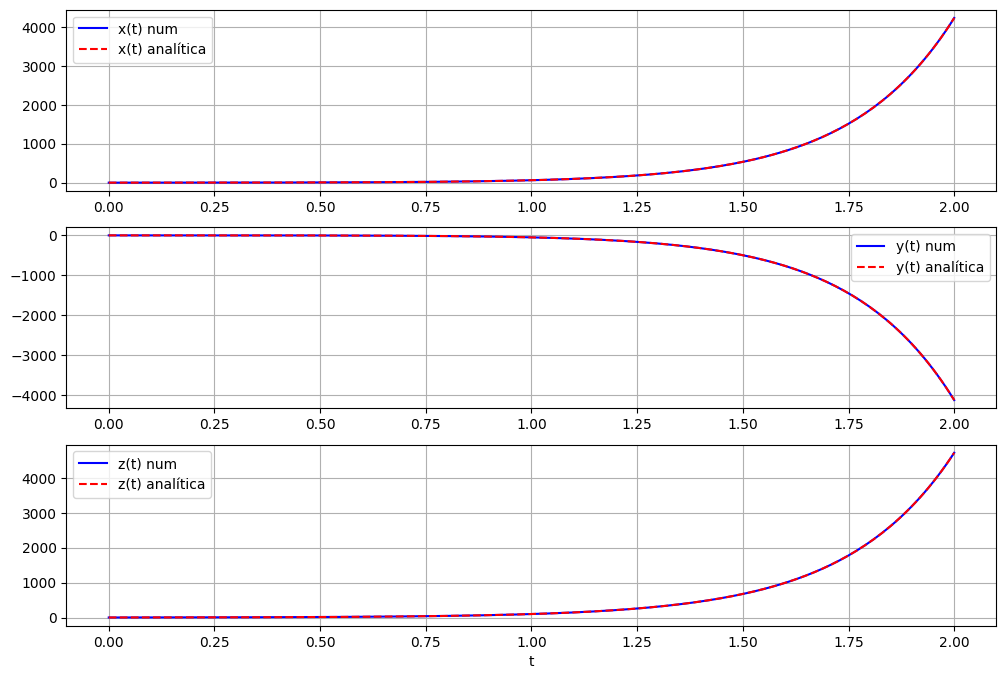

In [ ]:
# ejercicio 3
import matplotlib.pyplot as plt
from scipy.linalg import expm

# Matriz del sistema
A = np.array([[2, -1,  1], [0,  3, -1], [2,  1,  3]])

# Autovalores y autovectores
eigvals, U = np.linalg.eig(A)
D = np.diag(eigvals)
U_inv = np.linalg.inv(U)

print("Eigenvalues:")
print(eigvals)
print("\nMatrix U:")
print(U)
print("\nMatrix D:")
print(D)

# Condición inicial
r0 = np.array([1, 1, 2])
t = np.linspace(0, 2, 200)
# Solución numérica usando e^{At}
sol = np.zeros((len(t), 3))
for i, ti in enumerate(t):
    sol[i] = expm(A * ti) @ r0
x_num = sol[:, 0]
y_num = sol[:, 1]
z_num = sol[:, 2]
x0, y0, z0 = r0

x_ana = 0.5 * (x0 * (np.exp(2*t) * (1 + np.exp(2*t) - 2*t)) +
    y0 * (-2*t * np.exp(2*t)) +
    z0 * (np.exp(2*t) * (-1 + np.exp(2*t))))

y_ana = 0.5 * ( x0 * (-np.exp(2*t) * (-1 + np.exp(2*t) - 2*t)) +
    y0 * (2*(t + 1)*np.exp(2*t)) +
    z0 * (-np.exp(2*t) * (-1 + np.exp(2*t))))

z_ana = 0.5 * (x0 * (np.exp(2*t) * (-1 + np.exp(2*t) + 2*t)) +
    y0 * (2*t * np.exp(2*t)) +
    z0 * (np.exp(2*t) * (1 + np.exp(2*t))))

plt.figure(figsize=(12, 8))
plt.subplot(3,1,1)
plt.plot(t, x_num, 'b', label='x(t) num')
plt.plot(t, x_ana, 'r--', label='x(t) analítica')
plt.legend()
plt.grid()
plt.subplot(3,1,2)
plt.plot(t, y_num, 'b', label='y(t) num')
plt.plot(t, y_ana, 'r--', label='y(t) analítica')
plt.legend()
plt.grid()
plt.subplot(3,1,3)
plt.plot(t, z_num, 'b', label='z(t) num')
plt.plot(t, z_ana, 'r--', label='z(t) analítica')
plt.legend()
plt.grid()
plt.xlabel("t")
plt.show()


In [ ]:
#ejercicio 4

def power_method(A, tol=1e-7, max_iter=1000):
    n = A.shape[0]
    # Vector inicial aleatorio
    q = np.random.rand(n)
    q = q / np.linalg.norm(q)

    lambda_old = 0.0

    for k in range(1, max_iter + 1):
        z = A @ q
        q = z / np.linalg.norm(z)

        lambda_new = q.T @ A @ q

        # criterio de parada
        if abs(lambda_new - lambda_old) < tol * abs(lambda_new):
            return lambda_new, q, k, abs(lambda_new - lambda_old)
        lambda_old = lambda_new
    # Si no converge
    return lambda_new, q, max_iter, abs(lambda_new - lambda_old)
    np.random.seed(0)

M = np.random.rand(6, 6)
A = (M + M.T) / 2  # matriz simétrica
lambda_pm, v_pm, iters, err = power_method(A)
print("Power Method results:")
print("Lambda max =", lambda_pm)
print("v_max =", v_pm)
print("Iterations =", iters)
print("Last relative variation =", err)

eigvals, eigvecs = np.linalg.eig(A)

idx = np.argmax(np.abs(eigvals))
lambda_np = eigvals[idx]
v_np = eigvecs[:, idx] / np.linalg.norm(eigvecs[:, idx])

print("\nNumPy results:")
print("Lambda max =", lambda_np)
print("v_max =", v_np)
print("\nComparison:")
print("Eigenvalue difference =", abs(lambda_pm - lambda_np))
print("Eigenvector difference (norm) =", np.linalg.norm(v_pm - v_np))


Power Method results:
Lambda max = 2.9091296258232244
v_max = [0.43500103 0.4427827  0.43280784 0.33964254 0.41776506 0.37082376]
Iterations = 6
Last relative variation = 4.4862814796431394e-08

NumPy results:
Lambda max = 2.909129629057905
v_max = [0.4350179  0.44276981 0.43281061 0.33965033 0.41776874 0.37080485]

Comparison:
Eigenvalue difference = 3.234680523434008e-09
Eigenvector difference (norm) = 2.9842526751115443e-05


In [ ]:
#ejercicio 5
# Constantes
gamma = 2
hbar = 1

# Campo magnético
Bx = 0
By = 0
Bz = 1

# Hamiltoniano
H = -(gamma * hbar / 2) * np.array([[Bz, Bx - 1j*By], [Bx + 1j*By, -Bz]])

print("Hamiltoniano H:")
print(H)

# 1. Verificar que H es Hermitiano
print("\n¿H es hermitiano?")
print(np.allclose(H, H.conj().T))

# 2. Autovalores y autovectores
eigenvalues, eigenvectors = np.linalg.eig(H)
print("\nAutovalores (niveles de energía):")
print(eigenvalues)
print("\nAutovectores:")
print(eigenvectors)

# 3. Verificar normalización de los autovectores
print("\nNormas de los autovectores:")
for i in range(eigenvectors.shape[1]):
    norm = np.linalg.norm(eigenvectors[:, i])
    print(f"Vector {i+1}: norma = {norm}")

Hamiltoniano H:
[[-1.+0.j -0.+0.j]
 [-0.+0.j  1.-0.j]]

¿H es hermitiano?
True

Autovalores (niveles de energía):
[-1.+0.j  1.-0.j]

Autovectores:
[[1.+0.j 0.+0.j]
 [0.+0.j 1.+0.j]]

Normas de los autovectores:
Vector 1: norma = 1.0
Vector 2: norma = 1.0
